In [3]:
from data_loaders import DataLoader 
import torch 

In [ ]:
class resilienceStats:
    def __init__(self, freq_threshold):
        self.freq_threshold = freq_threshold

    def lag_1_autocorrelation_pre_drop(self, month_data):
        data = torch.tensor(month_data["f"].to_numpy())
        #this time we want to work out, prior to each drop below 48.8, was there a change in the lag-1 autocorrelation 
        #what would our plot actually be of? 
        #the x axis should be the frequency drop 
        #the y axis should be the lag-1 autocorrelation 
        drop_instances = None 

    def lag1_autocorrelation(self, data):
        x = data[:-1]
        y = data[1:]
        x = x - x.mean()
        y = y - y.mean()
        numerator = torch.sum(x * y)
        denominator = torch.sqrt(
            torch.sum(x**2) * torch.sum(y**2)
        )
        if denominator == 0:
            return torch.tensor(float('nan'), device=data.device)
        return numerator / denominator

    def get_daily_autocorrelations(self, month_data):
        #month_data = torch.tensor(month_data["f"].to_numpy())
        seconds_per_day = 86400

        number_of_days = len(month_data) // seconds_per_day

        daily_data = month_data[:number_of_days * seconds_per_day]

        daily_data = daily_data.reshape(number_of_days, seconds_per_day)

        daily_correlations = torch.stack([
            self.lag1_autocorrelation(day) for day in daily_data
        ])
        return daily_correlations

    def get_mean_daily_lag1(self, month_data):
    
        daily_correlations = self.get_daily_autocorrelations(month_data)
    
        return torch.nanmean(daily_correlations)
    
    def get_variance_daily_lag1(self, month_data):

        daily_correlations = self.get_daily_autocorrelations(month_data)

        return torch.var(daily_correlations)

    def get_monthly_lag1(self, month_data):

        return self.lag1_autocorrelation(month_data)


    def get_pre_event_autocorrelation(self, month_data):
        month_data = torch.tmonth_data["f"].to_numpy()
        thresholds = [49.0, 49.2, 49.5, 49.8]
        window_size = 900

        results = []

        for threshold in thresholds:
            # Identify downward threshold crossings
            crossings = torch.where(
                (month_data[:-1] >= threshold) &
                (month_data[1:] < threshold)
            )[0] + 1

            correlations = []

            for index in crossings:

                # Ensure 900 previous observations exist
                if index < window_size:
                    continue

                # Extract the 900 observations preceding the crossing
                window = month_data[index-window_size:index]

                correlation = self.lag1_autocorrelation(window)

                correlations.append(correlation)

            if len(correlations) > 0:
                results.append(torch.nanmean(torch.stack(correlations)))
            else:
                results.append(torch.tensor(float('nan'),
                                            device=month_data.device))

        return torch.stack(results)

    def get_different_outage_levels(self, month_data):
        data = torch.tensor(month_data["f"].to_numpy())
        outage_levels = [48.8, 49.2, 49.5, 49.8]
        outage_values = []
        for x in outage_levels:
            outage_values.append((data < x).sum())
        return outage_values


In [ ]:
directory = "D:/group project data/frequency_data"
years = [x for x in range(2016, 2026)]
months = [x for x in range(1, 13)]
dataloader = DataLoader(directory, years, months)
stats = resilienceStats(48.8)
result1 = dataloader.run_on_data(stats.get_mean_daily_lag1)
print(result1)

found 2016/1
2016/1 evaluated
found 2016/2
2016/2 evaluated
found 2016/3
2016/3 evaluated
found 2016/4
2016/4 evaluated
found 2016/5
2016/5 evaluated
found 2016/6
2016/6 evaluated
found 2016/7
2016/7 evaluated
found 2016/8
2016/8 evaluated
found 2016/9
2016/9 evaluated
found 2016/10
2016/10 evaluated
found 2016/11
2016/11 evaluated
found 2016/12
2016/12 evaluated
found 2017/1
2017/1 evaluated
found 2017/2
2017/2 evaluated
found 2017/3
2017/3 evaluated
found 2017/4
2017/4 evaluated
found 2017/5
2017/5 evaluated
found 2017/6
2017/6 evaluated
found 2017/7
2017/7 evaluated
found 2017/8
2017/8 evaluated
found 2017/9
2017/9 evaluated
found 2017/10
2017/10 evaluated
found 2017/11
2017/11 evaluated
found 2017/12
2017/12 evaluated
found 2018/1
2018/1 evaluated
found 2018/2
2018/2 evaluated
found 2018/3
2018/3 evaluated
found 2018/4
2018/4 evaluated
found 2018/5
2018/5 evaluated
found 2018/6
2018/6 evaluated
found 2018/7
2018/7 evaluated
found 2018/8
2018/8 evaluated
found 2018/9
2018/9 evaluate

Text(0, 0.5, 'mean daily lag-1 autocorrelation for month')

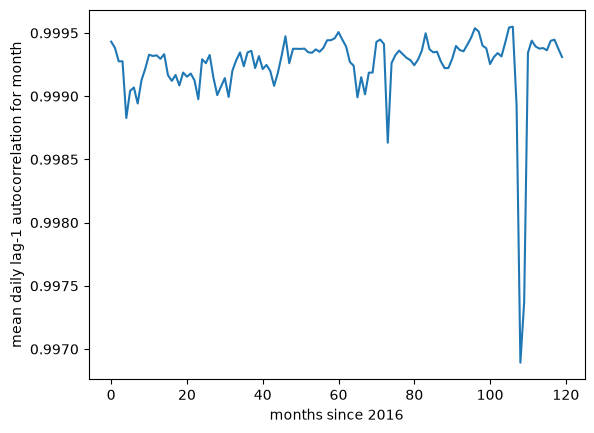

In [19]:
import matplotlib.pyplot as plt 
plt.plot([x for x in range(len(result1))], result1)
plt.xlabel("months since 2016")
plt.ylabel("mean daily lag-1 autocorrelation for month")

In [14]:
directory = "D:/group project data/frequency_data"
years =  [x for x in range(2016, 2026)]
months = [x for x in range(1, 13)]

dataloader = DataLoader(directory, years, months)
stats = resilienceStats(48.8)
result = dataloader.run_on_data(stats.get_variance_daily_lag1)
print(result)


found 2016/1
2016/1 evaluated
found 2016/2
2016/2 evaluated
found 2016/3
2016/3 evaluated
found 2016/4
2016/4 evaluated
found 2016/5
2016/5 evaluated
found 2016/6
2016/6 evaluated
found 2016/7
2016/7 evaluated
found 2016/8
2016/8 evaluated
found 2016/9
2016/9 evaluated
found 2016/10
2016/10 evaluated
found 2016/11
2016/11 evaluated
found 2016/12
2016/12 evaluated
found 2017/1
2017/1 evaluated
found 2017/2
2017/2 evaluated
found 2017/3
2017/3 evaluated
found 2017/4
2017/4 evaluated
found 2017/5
2017/5 evaluated
found 2017/6
2017/6 evaluated
found 2017/7
2017/7 evaluated
found 2017/8
2017/8 evaluated
found 2017/9
2017/9 evaluated
found 2017/10
2017/10 evaluated
found 2017/11
2017/11 evaluated
found 2017/12
2017/12 evaluated
found 2018/1
2018/1 evaluated
found 2018/2
2018/2 evaluated
found 2018/3
2018/3 evaluated
found 2018/4
2018/4 evaluated
found 2018/5
2018/5 evaluated
found 2018/6
2018/6 evaluated
found 2018/7
2018/7 evaluated
found 2018/8
2018/8 evaluated
found 2018/9
2018/9 evaluate

120


Text(0, 0.5, 'mean daily lag-1 autcorr variance over month')

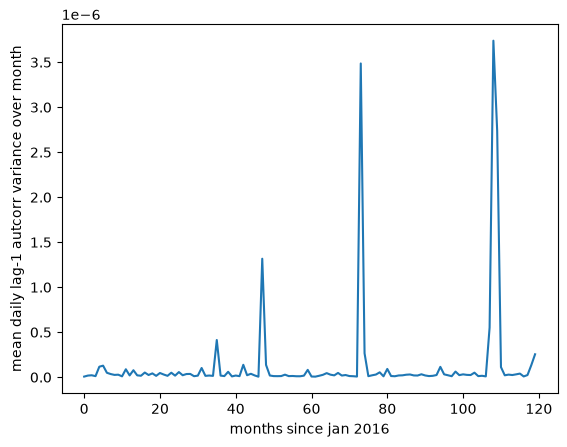

In [17]:
print(len(result))
plt.plot([x for x in range(len(result))], result)
plt.xlabel("months since jan 2016")
plt.ylabel("mean daily lag-1 autcorr variance over month")

In [22]:
directory = "D:/group project data/frequency_data"
years =  [x for x in range(2016, 2026)]
months = [x for x in range(1, 13)]

dataloader = DataLoader(directory, years, months)
stats = resilienceStats(48.8)
result = dataloader.run_on_data(stats.get_pre_event_autocorrelation)

found 2016/1
2016/1 evaluated
found 2016/2
2016/2 evaluated
found 2016/3
2016/3 evaluated
found 2016/4
2016/4 evaluated
found 2016/5
2016/5 evaluated
found 2016/6
2016/6 evaluated
found 2016/7
2016/7 evaluated
found 2016/8
2016/8 evaluated
found 2016/9
2016/9 evaluated
found 2016/10
2016/10 evaluated
found 2016/11
2016/11 evaluated
found 2016/12
2016/12 evaluated
found 2017/1
2017/1 evaluated
found 2017/2
2017/2 evaluated
found 2017/3
2017/3 evaluated
found 2017/4
2017/4 evaluated
found 2017/5
2017/5 evaluated
found 2017/6
2017/6 evaluated
found 2017/7
2017/7 evaluated
found 2017/8
2017/8 evaluated
found 2017/9
2017/9 evaluated
found 2017/10
2017/10 evaluated
found 2017/11
2017/11 evaluated
found 2017/12
2017/12 evaluated
found 2018/1
2018/1 evaluated
found 2018/2
2018/2 evaluated
found 2018/3
2018/3 evaluated
found 2018/4
2018/4 evaluated
found 2018/5
2018/5 evaluated
found 2018/6
2018/6 evaluated
found 2018/7
2018/7 evaluated
found 2018/8
2018/8 evaluated
found 2018/9
2018/9 evaluate

In [42]:
print(result[0][0])

tensor(nan, dtype=torch.float64)


In [43]:
larger_outage_autocorrelations = []
for x in range(len(result)): 
    if result[x][0] != result[0][0]:
        larger_outage_autocorrelations.append(x)
print(larger_outage_autocorrelations)


[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119]


[tensor(0.9925, dtype=torch.float64), tensor(0.9994, dtype=torch.float64), tensor(0.9968, dtype=torch.float64), tensor(0.9973, dtype=torch.float64), tensor(0.9969, dtype=torch.float64), tensor(0.9958, dtype=torch.float64), tensor(0.9981, dtype=torch.float64), tensor(0.9974, dtype=torch.float64), tensor(0.9965, dtype=torch.float64), tensor(0.9986, dtype=torch.float64), tensor(0.9976, dtype=torch.float64), tensor(0.9984, dtype=torch.float64), tensor(0.9992, dtype=torch.float64), tensor(0.9988, dtype=torch.float64), tensor(0.9983, dtype=torch.float64), tensor(0.9987, dtype=torch.float64), tensor(0.9959, dtype=torch.float64), tensor(0.9984, dtype=torch.float64), tensor(0.9970, dtype=torch.float64), tensor(0.9952, dtype=torch.float64), tensor(0.9980, dtype=torch.float64), tensor(0.9987, dtype=torch.float64), tensor(0.9983, dtype=torch.float64), tensor(0.9985, dtype=torch.float64), tensor(0.9978, dtype=torch.float64), tensor(0.9987, dtype=torch.float64), tensor(0.9989, dtype=torch.float64), 

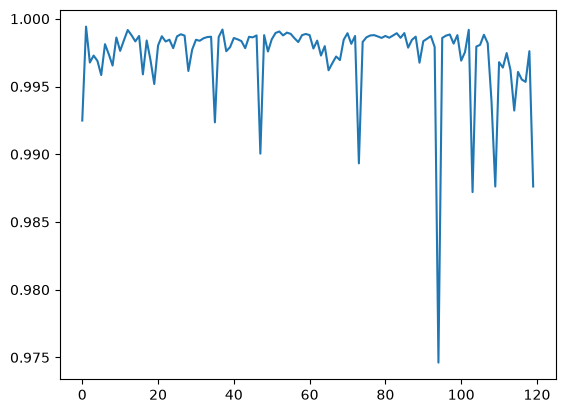

In [28]:
highestThreshold = []
for x in result:
    highestThreshold.append(x[-1])
print(highestThreshold)

plt.plot([x for x in range(len(highestThreshold))], highestThreshold)


In [19]:
directory = "D:/group project data/frequency_data"
years =  [x for x in range(2016, 2026)]
months = [x for x in range(1, 13)]

dataloader = DataLoader(directory, years, months)
stats = resilienceStats(48.8)
result = dataloader.run_on_data(stats.get_different_outage_levels)


found 2016/1
2016/1 evaluated
found 2016/2
2016/2 evaluated
found 2016/3
2016/3 evaluated
found 2016/4
2016/4 evaluated
found 2016/5
2016/5 evaluated
found 2016/6
2016/6 evaluated
found 2016/7
2016/7 evaluated
found 2016/8
2016/8 evaluated
found 2016/9
2016/9 evaluated
found 2016/10
2016/10 evaluated
found 2016/11
2016/11 evaluated
found 2016/12
2016/12 evaluated
found 2017/1
2017/1 evaluated
found 2017/2
2017/2 evaluated
found 2017/3
2017/3 evaluated
found 2017/4
2017/4 evaluated
found 2017/5
2017/5 evaluated
found 2017/6
2017/6 evaluated
found 2017/7
2017/7 evaluated
found 2017/8
2017/8 evaluated
found 2017/9
2017/9 evaluated
found 2017/10
2017/10 evaluated
found 2017/11
2017/11 evaluated
found 2017/12
2017/12 evaluated
found 2018/1
2018/1 evaluated
found 2018/2
2018/2 evaluated
found 2018/3
2018/3 evaluated
found 2018/4
2018/4 evaluated
found 2018/5
2018/5 evaluated
found 2018/6
2018/6 evaluated
found 2018/7
2018/7 evaluated
found 2018/8
2018/8 evaluated
found 2018/9
2018/9 evaluate

we could do some more work with determining the significance of the difference in lag-1 autocorrelation compared to during normal data operation? 



In [ ]:
print(result)
print(result[0][0] + result[0][3])

[[tensor(0), tensor(0), tensor(0), tensor(91)], [tensor(0), tensor(0), tensor(0), tensor(37)], [tensor(0), tensor(0), tensor(0), tensor(244)], [tensor(0), tensor(0), tensor(0), tensor(314)], [tensor(0), tensor(0), tensor(0), tensor(183)], [tensor(0), tensor(0), tensor(0), tensor(300)], [tensor(0), tensor(0), tensor(0), tensor(185)], [tensor(0), tensor(0), tensor(0), tensor(170)], [tensor(0), tensor(0), tensor(0), tensor(85)], [tensor(0), tensor(0), tensor(0), tensor(378)], [tensor(0), tensor(0), tensor(0), tensor(726)], [tensor(0), tensor(0), tensor(0), tensor(222)], [tensor(0), tensor(0), tensor(0), tensor(440)], [tensor(0), tensor(0), tensor(0), tensor(394)], [tensor(0), tensor(0), tensor(0), tensor(378)], [tensor(0), tensor(0), tensor(0), tensor(203)], [tensor(0), tensor(0), tensor(0), tensor(272)], [tensor(0), tensor(0), tensor(0), tensor(19)], [tensor(0), tensor(0), tensor(0), tensor(191)], [tensor(0), tensor(0), tensor(0), tensor(267)], [tensor(0), tensor(0), tensor(0), tensor(28

[[tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(1), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0), tensor(0

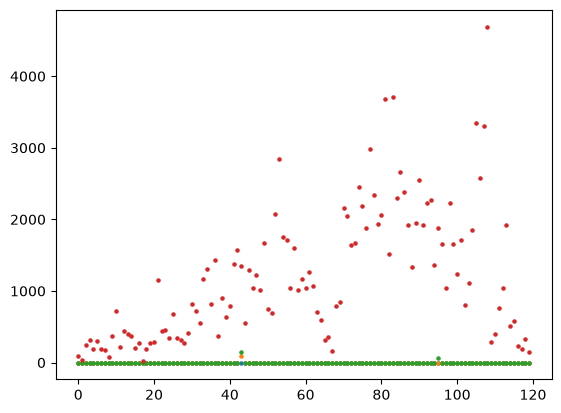

In [ ]:
array = [[], [], [], []]
for x in result:
    for y in range(len(x)):
        array[y].append(x[y])

print(array)
import matplotlib.pyplot as plt 
for x in array:
    plt.scatter([y for y in range(len(x))], x, s=5)
plt.show()
# possibly the least enlightening statistic of all time, but hey, at least we tried 

In [9]:
import os 
import pandas as pd 

In [ ]:
class DataLoader:
    def __init__(self, directory, years, months):
        self.directory = directory
        self.years = years
        self.months = months 

    def get_file_location(self, year, month):
        poss_formats = [f"f-{year}-{month}.csv", f"fnew-{year}-{month}.csv", f"fNew {year} {month}.csv", f"f {year} {month}.csv"]
        for x in poss_formats:
            path = os.path.join(self.directory, x)
            if os.path.exists(path):
                print(f"found {year}/{month}")
                return path 
        raise FileNotFoundError(F"couldn't find file {year}/{month} with any of the specified formats")


    def run_on_data(self, func):
        output = []
        for year in self.years:
            for month in self.months:
                loc = self.get_file_location(year, month)
                data = pd.read_csv(loc)
                output.append(func(data))
                print(f"{year}/{month} evaluated")
        return output 